In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data=pd.read_csv('/content/adult_dataset.csv')
data.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:
data.shape

(48842, 15)

In [ ]:
data.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


#missing values

In [ ]:
data.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [ ]:
data['native-country'].nunique()

42

#handling missing values

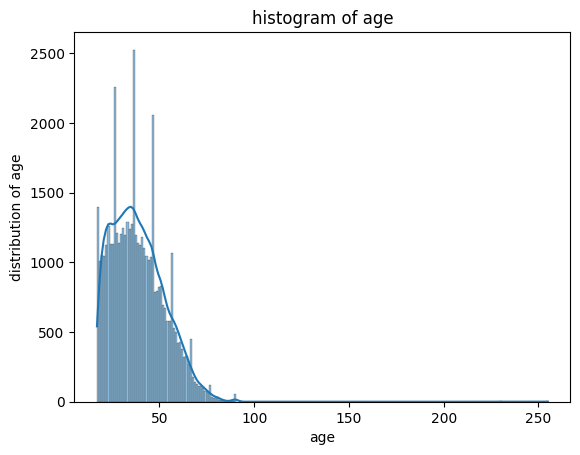

In [ ]:
sns.histplot(data['age'],kde=True)
plt.title("histogram of age")
plt.xlabel('age')
plt.ylabel('distribution of age')
plt.show()

since it is skewed median is used to fill the missing values

In [ ]:
data['age'].median()

37.0

In [ ]:
data['age']=data['age'].fillna(data['age'].median())

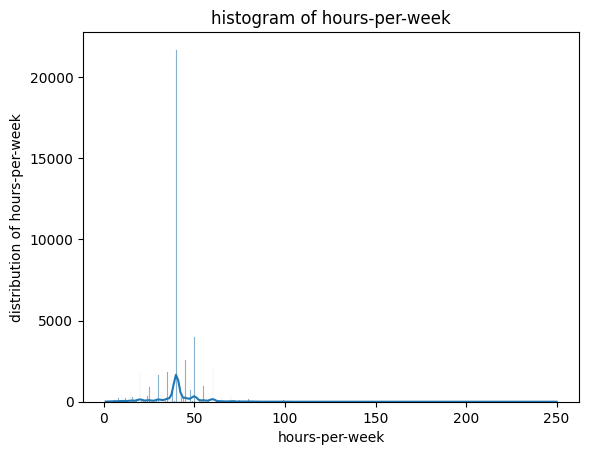

In [ ]:
sns.histplot(data['hours-per-week'],kde=True)
plt.title("histogram of hours-per-week")
plt.xlabel('hours-per-week')
plt.ylabel('distribution of hours-per-week')
plt.show()

In [ ]:
data['hours-per-week'].median()

40.0

In [ ]:
data['hours-per-week']=data['hours-per-week'].fillna(data['hours-per-week'].median())

here workclass,occupation and native country are of obj format

In [ ]:
data['workclass'].unique()

array(['State-gov', 'Self-emp-not-inc', 'Private', 'Federal-gov', nan,
       'Local-gov', '?', 'Self-emp-inc', 'Without-pay', 'Never-worked'],
      dtype=object)

In [ ]:
data['workclass'] = data['workclass'].replace('?', np.nan)

In [ ]:
data['workclass'].value_counts()

,count
workclass,
Private,32220
Self-emp-not-inc,3649
Local-gov,2973
State-gov,1877
Self-emp-inc,1625
Federal-gov,1346
Without-pay,18
Never-worked,9


In [ ]:
data['workclass'].mode()[0]

'Private'

In [ ]:
data['workclass']=data['workclass'].fillna(data['workclass'].mode()[0])


In [ ]:
data['occupation'].unique()

array(['Adm-clerical', 'Exec-managerial', 'Handlers-cleaners',
       'Prof-specialty', 'Other-service', 'Sales', 'Craft-repair',
       'Transport-moving', 'Farming-fishing', 'Machine-op-inspct',
       'Tech-support', nan, 'Protective-serv', '?', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [ ]:
data['occupation'] = data['occupation'].replace('?', np.nan)

In [ ]:
data['occupation'].value_counts()

,count
occupation,
Prof-specialty,5854
Craft-repair,5791
Exec-managerial,5771
Adm-clerical,5329
Sales,5231
Other-service,4657
Machine-op-inspct,2874
Transport-moving,2238
Handlers-cleaners,1977


In [ ]:
data['occupation'].mode()[0]

'Prof-specialty'

In [ ]:
data['occupation']=data['occupation'].fillna(data['occupation'].mode()[0])


In [ ]:
data['native-country'].unique()


array([nan, 'United-States', 'Cuba', 'Jamaica', 'India', '?', 'Mexico',
       'South', 'Puerto-Rico', 'Honduras', 'England', 'Germany', 'Iran',
       'Philippines', 'Italy', 'Columbia', 'Cambodia', 'Thailand',
       'Canada', 'Ecuador', 'Laos', 'Taiwan', 'Haiti', 'Portugal',
       'Dominican-Republic', 'El-Salvador', 'Poland', 'France',
       'Guatemala', 'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Hong', 'Ireland', 'Hungary',
       'Holand-Netherlands'], dtype=object)

In [ ]:
data['native-country'].value_counts()

,count
native-country,
United-States,41622
Mexico,908
?,555
Philippines,282
Germany,194
Puerto-Rico,175
Canada,170
El-Salvador,147
India,143


In [ ]:
data['native-country'].mode()[0]

'United-States'

In [ ]:
data['native-country'] = data['native-country'].replace('?', np.nan)

In [ ]:
data['native-country']=data['native-country'].fillna(data['native-country'].mode()[0])

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             48842 non-null  float64
 1   workclass       48842 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      48842 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  48842 non-null  float64
 13  native-country  48842 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [ ]:
data['income'].unique()

array(['<=50K', '>50K', '<=50K.', '>50K.'], dtype=object)

In [ ]:
data['income'] = data['income'].replace('<=50K.', '<=50K')

In [ ]:
data['income'] = data['income'].replace('>50K.', '>50K')

In [ ]:
data['income'].unique()

array(['<=50K', '>50K'], dtype=object)

In [ ]:
data.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


#outliers

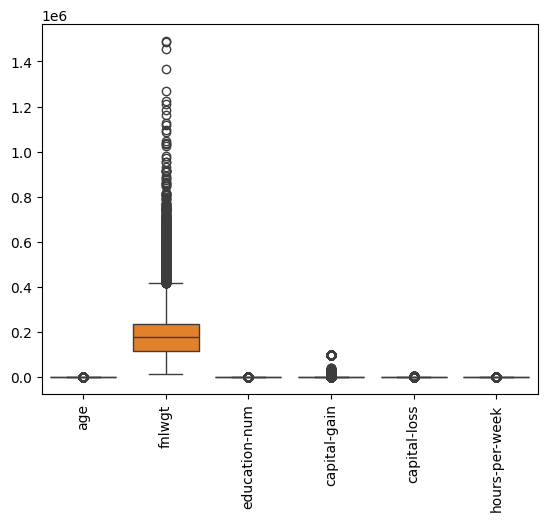

In [ ]:
sns.boxplot(data)
plt.xticks(rotation=90)
plt.show()

In [ ]:
#outlier count
numeric_cols = data.select_dtypes(include=['int64', 'float64']).columns

for col in numeric_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    outlier_count = ((data[col] < lower_limit) | (data[col] > upper_limit)).sum()
    print(f"{col}: {outlier_count} outliers")

age: 364 outliers
fnlwgt: 1453 outliers
education-num: 1794 outliers
capital-gain: 4035 outliers
capital-loss: 2282 outliers
hours-per-week: 12838 outliers


In [ ]:
Q1_age = data['age'].quantile(0.25)
Q3_age = data['age'].quantile(0.75)
IQR_age = Q3_age - Q1_age

lower_bound_age = Q1_age - 1.5 * IQR_age
upper_bound_age = Q3_age + 1.5 * IQR_age

Q1_min_hours_week = data['hours-per-week'].quantile(0.25)
Q3_min_hours_week = data['hours-per-week'].quantile(0.75)
IQR_min_hours_week = Q3_min_hours_week - Q1_min_hours_week

lower_bound_min_hours_week = Q1_min_hours_week - 1.5 * IQR_min_hours_week
upper_bound_min_hours_week = Q3_min_hours_week + 1.5 * IQR_min_hours_week

Q1_min_education_num = data['education-num'].quantile(0.25)
Q3_min_education_num = data['education-num'].quantile(0.75)
IQR_min_education_num = Q3_min_education_num - Q1_min_education_num

lower_bound_min_education_num = Q1_min_education_num - 1.5 * IQR_min_education_num
upper_bound_min_education_num = Q3_min_education_num + 1.5 * IQR_min_education_num

Q1_min_fnlwgt = data['fnlwgt'].quantile(0.25)
Q3_min_fnlwgt = data['fnlwgt'].quantile(0.75)
IQR_min_fnlwgt = Q3_min_fnlwgt - Q1_min_fnlwgt

lower_bound_min_fnlwgt = Q1_min_fnlwgt - 1.5 * IQR_min_fnlwgt
upper_bound_min_fnlwgt = Q3_min_fnlwgt + 1.5 * IQR_min_fnlwgt

data = data[
    (data['age'] > lower_bound_age) & (data['age'] < upper_bound_age) &
    (data['hours-per-week'] > lower_bound_min_hours_week) & (data['hours-per-week'] < upper_bound_min_hours_week) &
    (data['education-num'] > lower_bound_min_education_num) & (data['education-num'] < upper_bound_min_education_num) &
    (data['fnlwgt'] > lower_bound_min_fnlwgt) & (data['fnlwgt'] < upper_bound_min_fnlwgt)
]

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33567 entries, 0 to 48840
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             33567 non-null  float64
 1   workclass       33567 non-null  object 
 2   fnlwgt          33567 non-null  int64  
 3   education       33567 non-null  object 
 4   education-num   33567 non-null  int64  
 5   marital-status  33567 non-null  object 
 6   occupation      33567 non-null  object 
 7   relationship    33567 non-null  object 
 8   race            33567 non-null  object 
 9   sex             33567 non-null  object 
 10  capital-gain    33567 non-null  int64  
 11  capital-loss    33567 non-null  int64  
 12  hours-per-week  33567 non-null  float64
 13  native-country  33567 non-null  object 
 14  income          33567 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 4.1+ MB


In [ ]:
data['workclass'].unique()

array(['State-gov', 'Private', 'Self-emp-not-inc', 'Federal-gov',
       'Local-gov', 'Self-emp-inc', 'Never-worked', 'Without-pay'],
      dtype=object)

In [ ]:
data['education'].unique()

array(['Bachelors', 'HS-grad', '11th', 'Masters', 'Assoc-acdm',
       'Assoc-voc', '9th', 'Some-college', 'Doctorate', 'Prof-school',
       '10th', '12th'], dtype=object)

In [ ]:
data['marital-status'].unique()

array(['Never-married', 'Divorced', 'Married-civ-spouse', 'Separated',
       'Widowed', 'Married-spouse-absent', 'Married-AF-spouse'],
      dtype=object)

In [ ]:
data['occupation'].unique()

array(['Adm-clerical', 'Handlers-cleaners', 'Prof-specialty',
       'Exec-managerial', 'Sales', 'Craft-repair', 'Farming-fishing',
       'Machine-op-inspct', 'Transport-moving', 'Tech-support',
       'Protective-serv', 'Other-service', 'Armed-Forces',
       'Priv-house-serv'], dtype=object)

In [ ]:
data['relationship'].unique()

array(['Not-in-family', 'Husband', 'Wife', 'Own-child', 'Unmarried',
       'Other-relative'], dtype=object)

In [ ]:
data['race'].unique()


array(['White', 'Black', 'Asian-Pac-Islander', 'Other',
       'Amer-Indian-Eskimo'], dtype=object)

In [ ]:
data['sex'].unique()

array(['Male', 'Female'], dtype=object)

In [ ]:
data['native-country'].unique()


array(['United-States', 'Cuba', 'India', 'Puerto-Rico', 'Mexico',
       'England', 'Germany', 'Iran', 'Philippines', 'Italy', 'Cambodia',
       'Laos', 'Taiwan', 'Portugal', 'Poland', 'France', 'Canada',
       'El-Salvador', 'South', 'Dominican-Republic', 'Jamaica', 'Haiti',
       'China', 'Japan', 'Yugoslavia', 'Peru',
       'Outlying-US(Guam-USVI-etc)', 'Scotland', 'Trinadad&Tobago',
       'Greece', 'Nicaragua', 'Vietnam', 'Guatemala', 'Hong', 'Columbia',
       'Ireland', 'Ecuador', 'Honduras', 'Thailand', 'Hungary',
       'Holand-Netherlands'], dtype=object)

In [ ]:
data['income'].unique()

array(['<=50K', '>50K'], dtype=object)

#Encoding

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

In [ ]:
data.select_dtypes(include=['int','float']).columns

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

In [ ]:
data.select_dtypes(include=['object']).columns

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income'],
      dtype='object')

In [ ]:
#Define columns
numeric_col = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week']
categorical_col = ['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country', 'income']

In [ ]:
#Numerical pipeline
numerical_pipeline = Pipeline([('scaler',StandardScaler())])

In [ ]:
ordinal_col = ['education','occupation']

In [ ]:
onehot_col = ['workclass','marital-status','relationship', 'race', 'sex', 'native-country', 'income']

In [ ]:
#categorical pipeline
ordinal_pipeline = Pipeline([
    ('encoder', OrdinalEncoder(
        categories=[
            ['9th','10th','11th','12th','HS-grad','Some-college','Assoc-acdm','Assoc-voc','Bachelors','Masters','Prof-school','Doctorate'],
            ['Other-service', 'Priv-house-serv', 'Handlers-cleaners', 'Farming-fishing', 'Machine-op-inspct', 'Craft-repair',
             'Transport-moving', 'Sales', 'Adm-clerical', 'Tech-support', 'Protective-serv', 'Armed-Forces', 'Prof-specialty', 'Exec-managerial']
        ]))
    ])

categorical_pipeline = Pipeline([('encoder', OneHotEncoder(handle_unknown='ignore'))])

In [ ]:
#combine pipelines
preprocessor = ColumnTransformer([
    ('numeric',numerical_pipeline,numeric_col),
    ('ordinal',ordinal_pipeline,ordinal_col),
    ('onehot',categorical_pipeline,onehot_col)

])

In [ ]:
# Reconstruct X with all required columns for the preprocessor pipeline
X = data[numeric_col + ordinal_col + onehot_col].copy()

# Fit and transform
X_processed = preprocessor.fit_transform(X)

In [ ]:
X_processed

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 500469 stored elements and shape (33567, 79)>

#KMeans Cluster

In [ ]:
# using elbow method to find the optimum number of clusters
from sklearn.cluster import KMeans
wcss = []
for i in  range(3,9):
  kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42)
  kmeans.fit(X_processed)
  wcss.append (kmeans.inertia_)

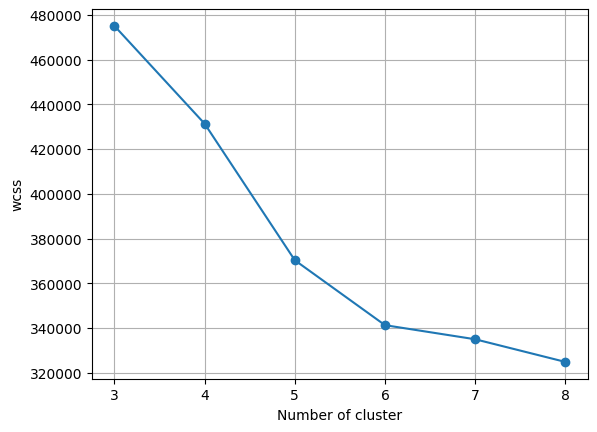

In [ ]:
plt.plot(range(3,9),wcss,'o-')
plt.xlabel('Number of cluster')
plt.ylabel('wcss')
plt.grid()

In [ ]:
#elbow at k= 6
# so no of  clusters = 6
kmeans1 = KMeans(n_clusters=6, init='k-means++', random_state=42)
y_kmeans = kmeans1.fit_predict(X_processed)

In [ ]:
y_kmeans

array([5, 3, 3, ..., 4, 2, 5], dtype=int32)

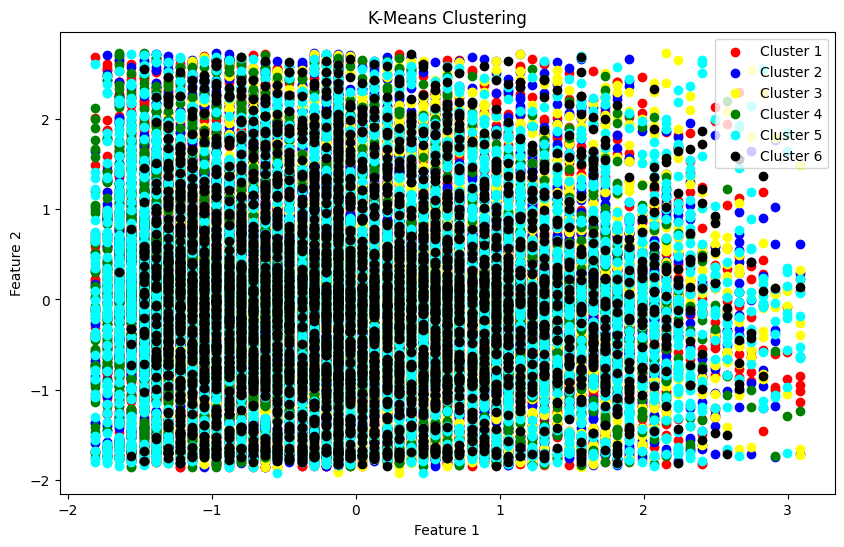

In [ ]:
X_dense = X_processed.toarray()

plt.figure(figsize=(10, 6))

plt.scatter(X_dense[y_kmeans == 0, 0], X_dense[y_kmeans == 0, 1], c='red', label='Cluster 1')
plt.scatter(X_dense[y_kmeans == 1, 0], X_dense[y_kmeans == 1, 1], c='blue', label='Cluster 2')
plt.scatter(X_dense[y_kmeans == 2, 0], X_dense[y_kmeans == 2, 1], c='yellow', label='Cluster 3')
plt.scatter(X_dense[y_kmeans == 3, 0], X_dense[y_kmeans == 3, 1], c='green', label='Cluster 4')
plt.scatter(X_dense[y_kmeans == 4, 0], X_dense[y_kmeans == 4, 1], c='cyan', label='Cluster 5')
plt.scatter(X_dense[y_kmeans == 5, 0], X_dense[y_kmeans == 5, 1], c='black', label='Cluster 6')

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means Clustering')
plt.legend()
plt.show()

In [ ]:
#silhouette score
from sklearn.metrics import silhouette_score
sil_kmeans=silhouette_score(X_processed,y_kmeans)

In [ ]:
sil_kmeans

np.float64(0.2255002652410346)

#Agglomerative Hierarchical Clustering


In [ ]:
# using dendrogram to find the optimum number of clusters
import scipy.cluster.hierarchy as sch

sch.dendrogram = sch.dendrogram(sch.linkage(X_dense, method = 'ward'))
plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Eucleadean Distance")
plt.show()

In [ ]:
import scipy.cluster.hierarchy as sch
import importlib

# Force reload scipy.cluster.hierarchy to recover the original 'dendrogram' function
importlib.reload(sch)

# Plot the dendrogram correctly using a distinct variable name for the output dictionary
plt.figure(figsize=(12, 6))
dendrogram_dict = sch.dendrogram(sch.linkage(X_dense, method='ward'))
plt.axhline(y=200, color='red', linestyle='--')
plt.title("Dendrogram with Threshold Line")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 4 , linkage= 'ward')
y_hc = hc.fit_predict(X_dense)

In [ ]:
silhouette_avg = silhouette_score(X_dense,y_hc)
print(silhouette_avg)